In [10]:
!pip install tensorflow pillow matplotlib numpy

In [11]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.utils import to_categorical
import pickle
import numpy as np
import os

# load cifar10 from local files (official download link was not working)
def load_cifar_batch(filepath):
    with open(filepath, 'rb') as f:
        batch = pickle.load(f, encoding='latin1')
    data = batch['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    labels = np.array(batch['labels'])
    return data, labels

cifar_dir = os.path.expanduser('~/.keras/datasets/cifar-10-batches-py')

x_train_list, y_train_list = [], []
for i in range(1, 6):
    data, labels = load_cifar_batch(os.path.join(cifar_dir, f'data_batch_{i}'))
    x_train_list.append(data)
    y_train_list.append(labels)

x_train = np.concatenate(x_train_list)
y_train = np.concatenate(y_train_list).reshape(-1, 1)

x_test, y_test = load_cifar_batch(os.path.join(cifar_dir, 'test_batch'))
y_test = y_test.reshape(-1, 1)

print("Loaded dataset:", x_train.shape, x_test.shape)

class_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                'dog', 'frog', 'horse', 'ship', 'truck']

# normalize
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255.0
x_test /= 255.0

# one hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# build model
model = Sequential()
model.add(Conv2D(32, (3, 3), padding='same', input_shape=(32, 32, 3), activation='relu'))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

model.summary()

# train
model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=12,
    validation_data=(x_test, y_test),
    shuffle=True
)

# evaluate
score = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {score[0]:.4f}")
print(f"Test accuracy: {score[1]*100:.2f}%")

# save
model.save('cifar10_cnn.h5')
print("Model saved as cifar10_cnn.h5")

Loaded dataset: (50000, 32, 32, 3) (10000, 32, 32, 3)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 30, 30, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 15, 15, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 13, 13, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 6, 6, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1152)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         590,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           5,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 642,570 (2.45 MB)

 Trainable params: 642,570 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.4431 - loss: 1.5221 - val_accuracy: 0.5923 - val_loss: 1.1427
Epoch 2/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.5926 - loss: 1.1548 - val_accuracy: 0.6569 - val_loss: 0.9840
Epoch 3/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.6447 - loss: 1.0039 - val_accuracy: 0.6916 - val_loss: 0.8827
Epoch 4/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.6802 - loss: 0.9213 - val_accuracy: 0.7143 - val_loss: 0.8242
Epoch 5/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.6976 - loss: 0.8684 - val_accuracy: 0.7181 - val_loss: 0.8121
Epoch 6/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.7150 - loss: 0.8172 - val_accuracy: 0.7316 - val_loss: 0.7757
Epoch 7/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.7264 - loss: 0.7820 - val_accuracy: 0.7338 - val_loss: 0.7572
Epoch 8/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.7380 -

Test loss: 0.6758
Test accuracy: 77.14%
Model saved as cifar10_cnn.h5


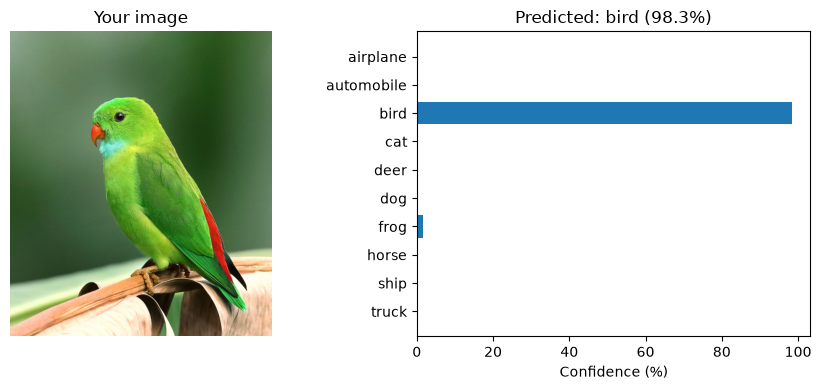

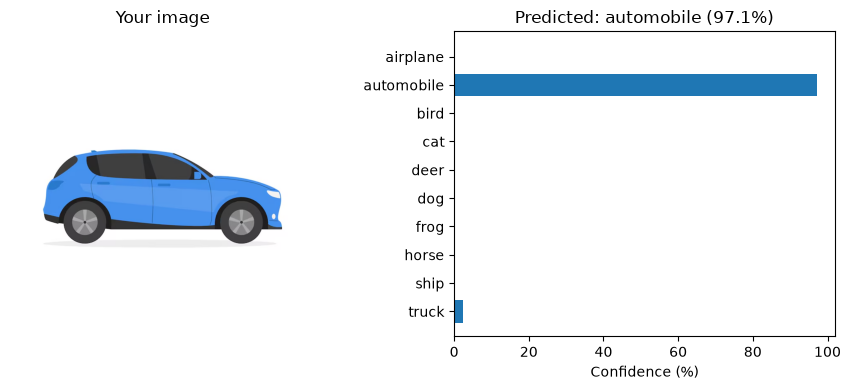

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from keras.models import load_model

class_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                'dog', 'frog', 'horse', 'ship', 'truck']

model = load_model('cifar10_cnn.h5', compile=False)

def predict(image_path):
    img = Image.open(image_path).convert("RGB")
    small = img.resize((32, 32))

    x = np.expand_dims(np.asarray(small, dtype="float32") / 255.0, 0)
    probs = model.predict(x, verbose=0)[0]
    best = int(np.argmax(probs))

    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    ax[0].imshow(img); ax[0].axis("off"); ax[0].set_title("Your image")
    ax[1].barh(class_labels, probs * 100)
    ax[1].invert_yaxis(); ax[1].set_xlabel("Confidence (%)")
    ax[1].set_title(f"Predicted: {class_labels[best]} ({probs[best]*100:.1f}%)")
    plt.tight_layout(); plt.show()

predict('bird.jpg')
predict('car.jpg')